# Week 5 - Deep dive analysis (master notebook)
**Questions.** Q3 cancellation concentration, Q5 customer lifetime value, Q6 margin concentration, Q7 lead-time seasonality, Q11 replenishment gate and scenario, Q12 ledger mismatches.

**What this notebook does.** Each question has its own self-contained notebook in `standalone_question_reports/` (written by its owner). This master notebook (1) re-runs all six from the repository, (2) confirms every one finishes with no errors and that every validation check passes, (3) rebuilds the combined `validation_report_week05.csv`, and (4) shows each question's answer, key tables and charts in one place. It does not repeat the analysis: the methods, tests and checks live in the question notebooks.

| Q | Owner | Notebook |
|---|---|---|
| Q3 | Salim Bello Muhammad | `q3_cancellation_concentration/` |
| Q5 | Salim Bello Muhammad | `q5_customer_lifetime_value/` |
| Q6 | Chandrashekhar Deurghare | `q6_margin_concentration/` |
| Q7 | Abdibasid Mohamed Ali | `q7_lead_time_seasonality/` |
| Q11 | Ibrahim Khalil Umar, with Abdibasid | `q11_stock_scale_gate/` |
| Q12 | Ibrahim Khalil Umar | `q12_ledger_mismatches/` |

Open this notebook anywhere inside the repository checkout and run all cells (about 1 to 2 minutes). Set `RUN_QUESTION_NOTEBOOKS = False` below to skip re-running and only collect the saved results.

In [1]:
import os, time, warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import pandas as pd, numpy as np
import nbformat
from nbclient import NotebookClient
from IPython.display import display, Image, Markdown
RUN_QUESTION_NOTEBOOKS = True
def find_week05():
    for base in [Path.cwd(), *Path.cwd().parents]:
        for rel in ["week-05", "."]:
            if (base / rel / "standalone_question_reports").exists():
                return (base / rel).resolve()
    return None
W5 = find_week05()
assert W5 is not None, "Could not find week-05/standalone_question_reports. Open this notebook inside the repository checkout."
SQ = W5 / "standalone_question_reports"
QUESTIONS = [  # (question, owner, folder, notebook, validation file, expected checks)
    ("Q3","Salim Bello Muhammad","q3_cancellation_concentration","q3_cancellation_concentration.ipynb","validation_report_week05_q3.csv",27),
    ("Q5","Salim Bello Muhammad","q5_customer_lifetime_value","q5_customer_lifetime_value.ipynb","validation_report_week05_q5.csv",34),
    ("Q6","Chandrashekhar Deurghare","q6_margin_concentration","q6_margin_concentration.ipynb","validation_report_week05_q6.csv",38),
    ("Q7","Abdibasid Mohamed Ali","q7_lead_time_seasonality","q7_lead_time_seasonality.ipynb","validation_report_week05_q7.csv",34),
    ("Q11","Ibrahim Khalil Umar","q11_stock_scale_gate","05_q11_stock_scale_gate_and_scenario.ipynb","validation_report_week05_q11.csv",16),
    ("Q12","Ibrahim Khalil Umar","q12_ledger_mismatches","05_q12_ledger_mismatches.ipynb","validation_report_week05_q12.csv",18),
]
checks=[]
def check(name,expected,actual,ok):
    checks.append(dict(Check_Item=name,Expected=expected,Actual=actual,Status="PASS" if ok else "FAIL")); assert ok,f"{name}: expected {expected}, got {actual}"
print("week-05 folder:",W5)

week-05 folder: /tmp/claude-0/-home-claude/e17ce6b6-afe8-5a4a-b191-c5fe2b31efe5/scratchpad/full/repo/week-05


## Part 0. Re-run every question notebook
Each notebook is executed from its own folder (so it writes its outputs, charts and validation file next to itself) and its output cells are scanned for errors. The notebooks themselves assert that every one of their checks passes.

In [2]:
runlog=[]
for q,owner,folder,nbname,vname,nexp in QUESTIONS:
    path=SQ/folder/nbname; check(f"{q}: notebook exists",True,path.exists(),path.exists())
    t0=time.time()
    if RUN_QUESTION_NOTEBOOKS:
        nbk=nbformat.read(path,as_version=4)
        NotebookClient(nbk,timeout=900,kernel_name="python3",resources={"metadata":{"path":str(SQ/folder)}}).execute()
    else:
        nbk=nbformat.read(path,as_version=4)
    errs=sum(o.output_type=="error" for c in nbk.cells if c.cell_type=="code" for o in c.get("outputs",[]))
    runlog.append(dict(question=q,owner=owner,notebook=nbname,executed_now=RUN_QUESTION_NOTEBOOKS,error_outputs=errs,seconds=round(time.time()-t0,1)))
    check(f"{q}: notebook finishes with no error outputs",0,errs,errs==0)
display(pd.DataFrame(runlog))

[IPKernelApp] WARNING | Kernel is running over TCP without encryption. All communication (including code and outputs) is sent in plain text and is susceptible to eavesdropping. Use IPC transport or launch with kernel manager-provisioned CurveZMQ keys to enable transport encryption.


[IPKernelApp] WARNING | Kernel is running over TCP without encryption. All communication (including code and outputs) is sent in plain text and is susceptible to eavesdropping. Use IPC transport or launch with kernel manager-provisioned CurveZMQ keys to enable transport encryption.


[IPKernelApp] WARNING | Kernel is running over TCP without encryption. All communication (including code and outputs) is sent in plain text and is susceptible to eavesdropping. Use IPC transport or launch with kernel manager-provisioned CurveZMQ keys to enable transport encryption.


[IPKernelApp] WARNING | Kernel is running over TCP without encryption. All communication (including code and outputs) is sent in plain text and is susceptible to eavesdropping. Use IPC transport or launch with kernel manager-provisioned CurveZMQ keys to enable transport encryption.


[IPKernelApp] WARNING | Kernel is running over TCP without encryption. All communication (including code and outputs) is sent in plain text and is susceptible to eavesdropping. Use IPC transport or launch with kernel manager-provisioned CurveZMQ keys to enable transport encryption.


[IPKernelApp] WARNING | Kernel is running over TCP without encryption. All communication (including code and outputs) is sent in plain text and is susceptible to eavesdropping. Use IPC transport or launch with kernel manager-provisioned CurveZMQ keys to enable transport encryption.


,question,owner,notebook,executed_now,error_outputs,seconds
0,Q3,Salim Bello Muhammad,q3_cancellation_concentration.ipynb,True,0,17.1
1,Q5,Salim Bello Muhammad,q5_customer_lifetime_value.ipynb,True,0,10.1
2,Q6,Chandrashekhar Deurghare,q6_margin_concentration.ipynb,True,0,17.5
3,Q7,Abdibasid Mohamed Ali,q7_lead_time_seasonality.ipynb,True,0,15.5
4,Q11,Ibrahim Khalil Umar,05_q11_stock_scale_gate_and_scenario.ipynb,True,0,6.4
5,Q12,Ibrahim Khalil Umar,05_q12_ledger_mismatches.ipynb,True,0,4.2


## Part 1. Validation: collect and combine
Every question notebook writes its own validation file. They are read here, checked for the expected number of checks and for all-pass, and combined into `validation_report_week05.csv` (columns: Question, Check_Item, Expected, Actual, Status). Q11 and Q12 use a `check, passed, detail` layout and are mapped onto the same columns.

In [3]:
parts=[]; summary=[]
for q,owner,folder,nbname,vname,nexp in QUESTIONS:
    v=pd.read_csv(SQ/folder/vname)
    if "Status" not in v.columns:
        v=pd.DataFrame({"Check_Item":v["check"],"Expected":"","Actual":v["detail"],"Status":v["passed"].astype(str).str.upper().map({"TRUE":"PASS","FALSE":"FAIL"})})
    v.insert(0,"Question",q); parts.append(v[["Question","Check_Item","Expected","Actual","Status"]])
    npass=int((v.Status=="PASS").sum()); summary.append(dict(question=q,owner=owner,checks=len(v),passed=npass))
    check(f"{q}: {nexp} checks present",nexp,len(v),len(v)==nexp)
    check(f"{q}: every check passes",len(v),npass,npass==len(v))
ALL=pd.concat(parts,ignore_index=True); ALL.to_csv(W5/"validation_report_week05.csv",index=False)
S=pd.DataFrame(summary); S.loc[len(S)]=dict(question="Total",owner="",checks=int(S.checks.sum()),passed=int(S.passed.sum()))
check("all Week 5 question checks combined: 167 of 167",167,int(S.passed.iloc[-1]),int(S.checks.iloc[-1])==167 and int(S.passed.iloc[-1])==167)
display(S)

,question,owner,checks,passed
0,Q3,Salim Bello Muhammad,27,27
1,Q5,Salim Bello Muhammad,34,34
2,Q6,Chandrashekhar Deurghare,38,38
3,Q7,Abdibasid Mohamed Ali,34,34
4,Q11,Ibrahim Khalil Umar,16,16
5,Q12,Ibrahim Khalil Umar,18,18
6,Total,,167,167


## Part 2. Answers and key results, question by question

### Q3. Where is cancellation concentrated?
**Not concentrated anywhere.** 1,967 of 20,000 orders cancelled (9.84%, ₹2.49B). Nothing is significant after adjusting for 12 cuts; whole-scan permutation p = 0.37. The 2019 to 2024 rise (9.1% to 10.9%) is weak, post-hoc evidence. No cancellation reason exists, and cancelled orders still carry a delivery date.

-- q3_cancellation_by_year.csv (6 rows)


,year,sum,count,rate_pct,ci_low_pct,ci_high_pct
0,2019,305,3336,9.143,8.211,10.168
1,2020,320,3358,9.529,8.582,10.569
2,2021,327,3365,9.718,8.762,10.765
3,2022,331,3279,10.095,9.110,11.173
4,2023,324,3346,9.683,8.727,10.732
5,2024,360,3316,10.856,9.843,11.961


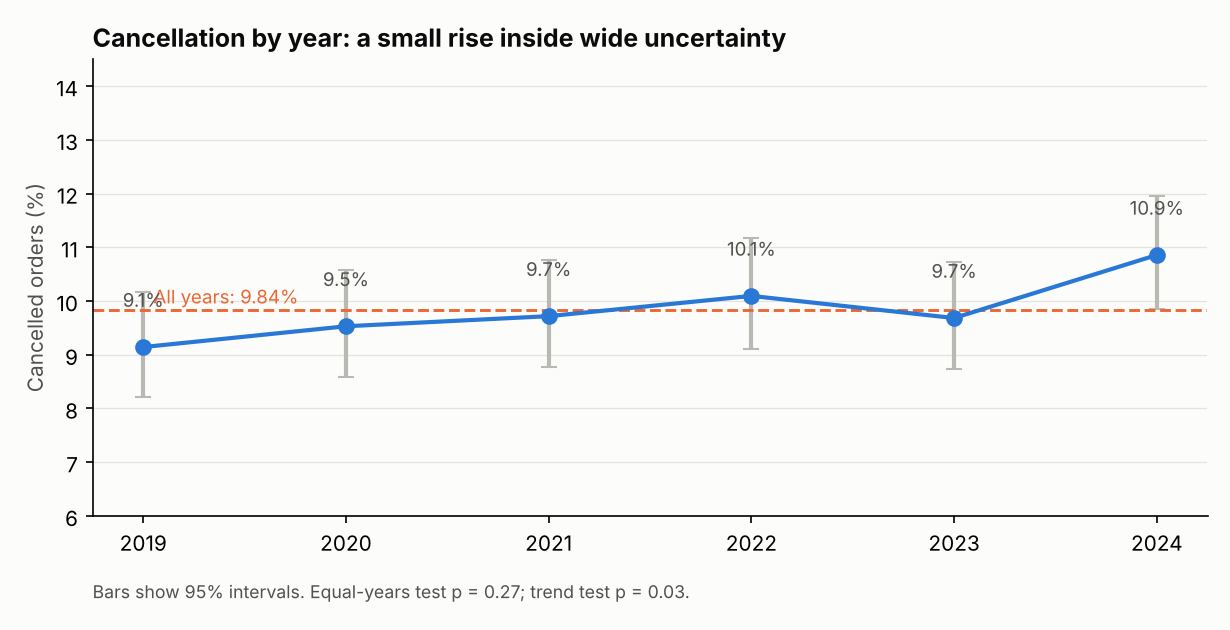

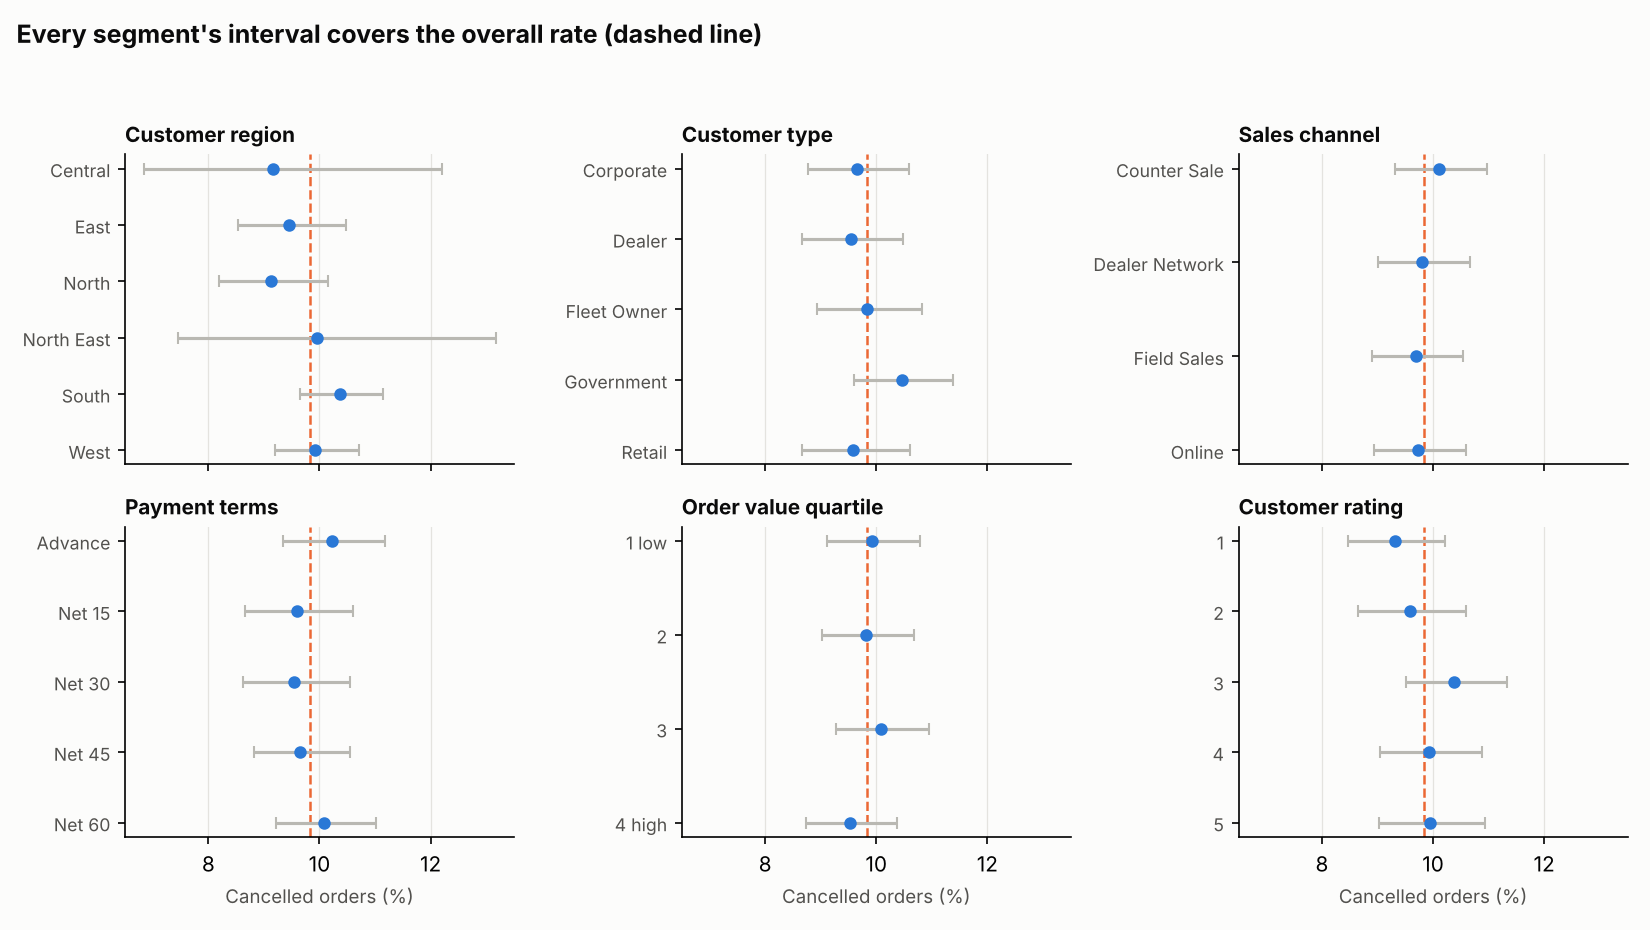

In [4]:
def show(q,folder,files=(),charts=(),n=12):
    for f in files:
        d=pd.read_csv(SQ/folder/f); print(f"-- {f} ({len(d)} rows)"); display(d.head(n).round(4))
    for c in charts:
        p=SQ/folder/c; check(f"{q}: chart {p.name} exists",True,p.exists(),p.exists()); display(Image(filename=str(p),width=720))
display(Markdown("### Q3. Where is cancellation concentrated?\n**Not concentrated anywhere.** 1,967 of 20,000 orders cancelled (9.84%, ₹2.49B). Nothing is significant after adjusting for 12 cuts; whole-scan permutation p = 0.37. The 2019 to 2024 rise (9.1% to 10.9%) is weak, post-hoc evidence. No cancellation reason exists, and cancelled orders still carry a delivery date."))
show("Q3","q3_cancellation_concentration/q3_outputs",files=["q3_cancellation_by_year.csv"],n=6)
for p in sorted((SQ/"q3_cancellation_concentration/q3_charts").glob("*.png"))[:2]: display(Image(filename=str(p),width=680))

### Q5. What is a customer worth over time?
**About the same whatever the type.** Mean observed gross profit ₹9.9M per customer (95% interval ₹9.7M to ₹10.1M); customer type does not matter (p = 0.41); no customer dominates (largest 0.37%, top 10% hold 14.2%). Industry segment is an **exploratory lead** to re-test (adjusted p = 0.059). The customer master dates are unreliable.

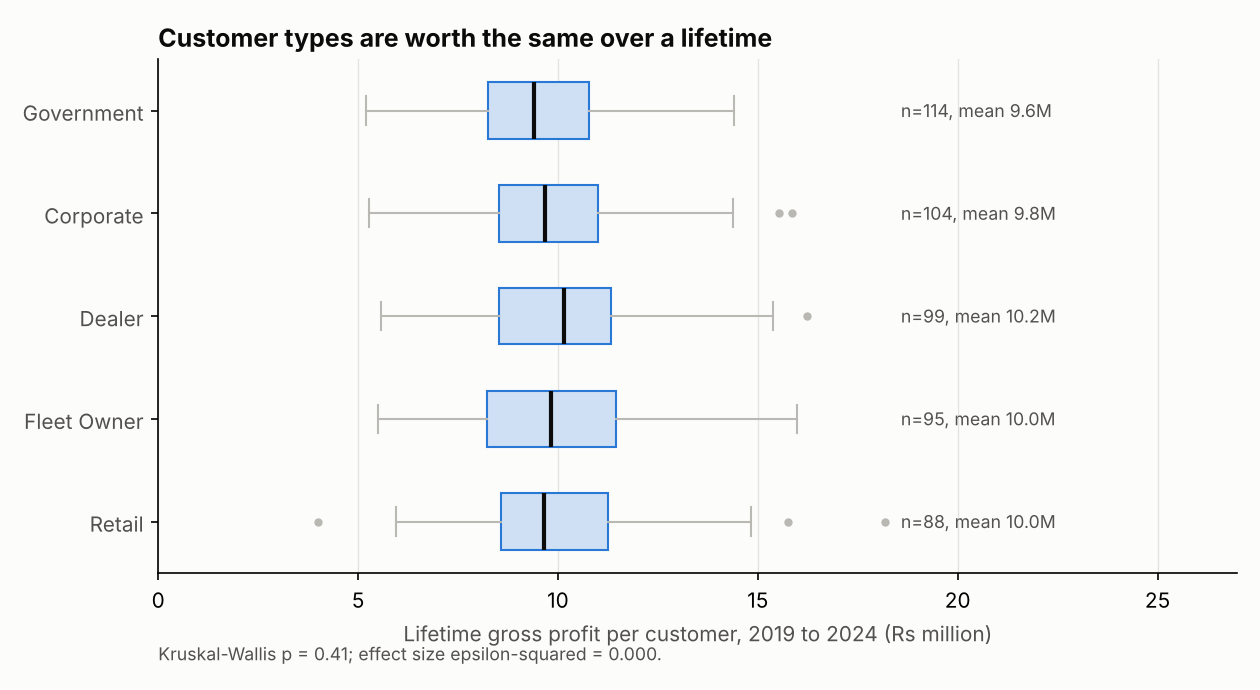

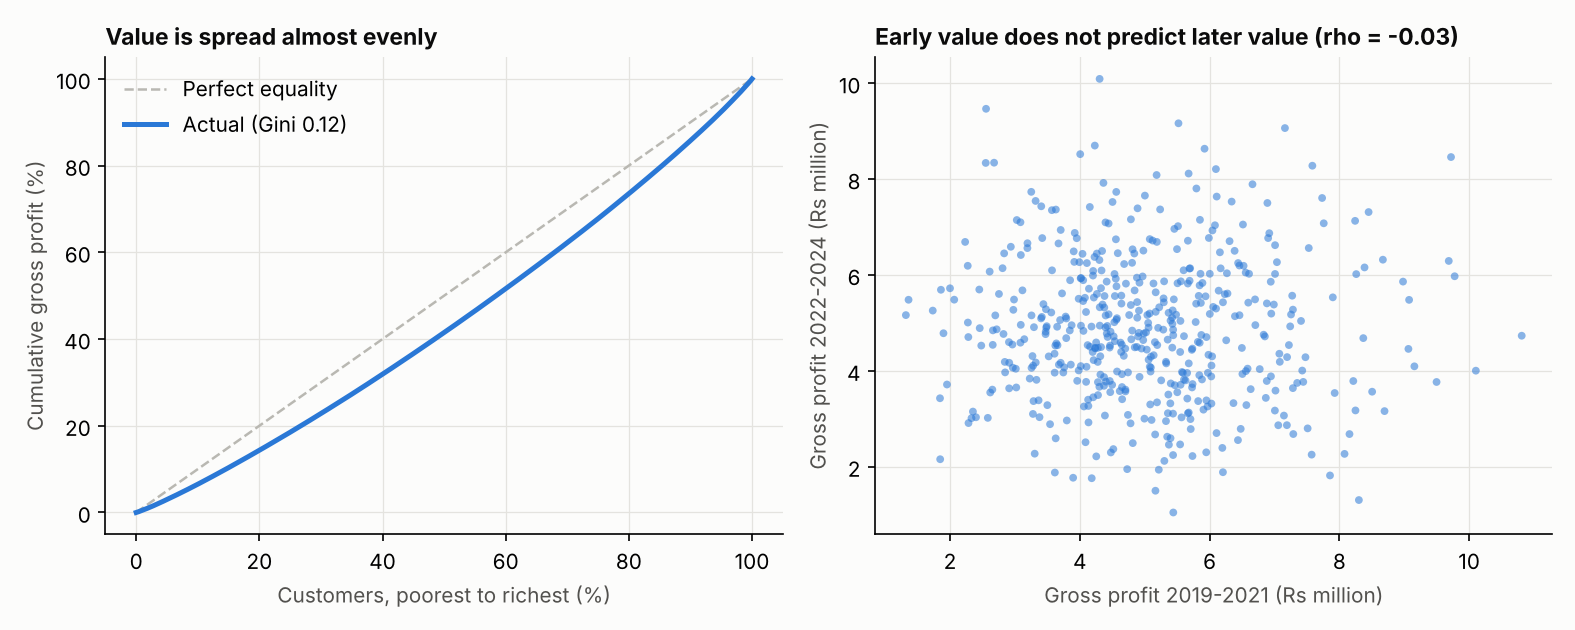

In [5]:
display(Markdown("### Q5. What is a customer worth over time?\n**About the same whatever the type.** Mean observed gross profit ₹9.9M per customer (95% interval ₹9.7M to ₹10.1M); customer type does not matter (p = 0.41); no customer dominates (largest 0.37%, top 10% hold 14.2%). Industry segment is an **exploratory lead** to re-test (adjusted p = 0.059). The customer master dates are unreliable."))
for p in sorted((SQ/"q5_customer_lifetime_value/q5_charts").glob("*.png"))[:2]: display(Image(filename=str(p),width=680))

### Q6. Where is margin concentrated?
**The drag, not the margin, is concentrated.** EB-600 and TA-800 are 35.9% of revenue but 31.7% of gross profit and pull the 21.56% portfolio margin down by 0.91 points (about ₹210M). Margin is stable over time. The price what-if is arithmetic only; the 2024 EB-600 fall is within chance.

-- q6_01_product_table.csv (30 rows)


,product_id,product_name,category,units,revenue,gross_profit,unit_price,unit_cost,margin_pct,revenue_share_pct,gp_share_pct,gp_minus_revenue_share_pts,margin_vs_portfolio_pts,contribution_to_gap_pts,gp_if_portfolio_margin,gp_shortfall_vs_portfolio_margin,revenue_rank,margin_rank
0,P015,Engine Block EB-600,Engine,40815,4856985000,959152500,119000,95500,19.7479,21.1550,19.3768,-1.7783,-1.8123,-0.3834,1.047176e+09,-8.802384e+07,1,27
1,P014,Transmission Assembly TA-800,Transmission,40574,3387929000,608610000,83500,68500,17.9641,14.7564,12.2951,-2.4613,-3.5961,-0.5307,7.304447e+08,-1.218347e+08,2,29
2,P021,Boom Cylinder BC-400,Hydraulic,41864,1934116800,443758400,46200,35600,22.9437,8.4242,8.9648,0.5406,1.3835,0.1165,4.169997e+08,2.675869e+07,3,22
3,P019,Swing Motor SWM-350,Hydraulic,41543,1653411400,357269800,39800,31200,21.6080,7.2016,7.2176,0.0160,0.0478,0.0034,3.564790e+08,7.907698e+05,4,26
4,P004,Track Chain TC-45,Undercarriage,40891,1627461800,298504300,39800,32500,18.3417,7.0886,6.0304,-1.0582,-3.2185,-0.2281,3.508842e+08,-5.237994e+07,5,28
5,P010,Turbocharger TB-900,Engine,42292,1475990800,253752000,34900,28900,17.1920,6.4288,5.1263,-1.3025,-4.3682,-0.2808,3.182268e+08,-6.447477e+07,6,30
6,P011,Hydraulic Cylinder HC-200,Hydraulic,42093,1161766800,256767300,27600,21500,22.1014,5.0602,5.1872,0.1270,0.5412,0.0274,2.504794e+08,6.287896e+06,7,25
7,P001,Hydraulic Pump HP-300,Hydraulic,41304,1011948000,229237200,24500,18950,22.6531,4.4076,4.6310,0.2234,1.0928,0.0482,2.181782e+08,1.105905e+07,8,24


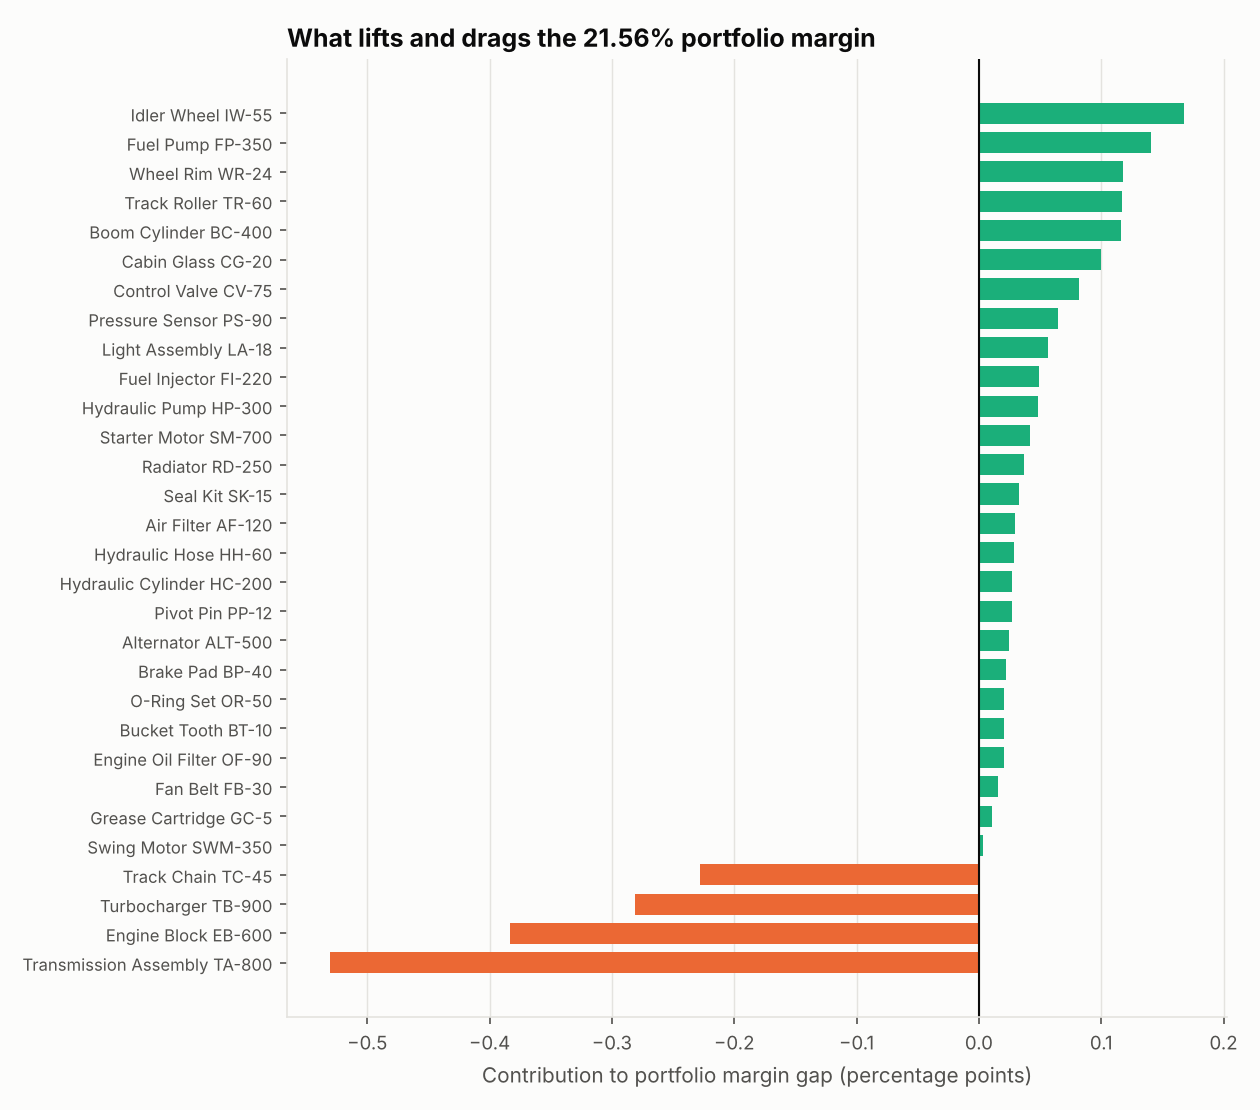

-- q6_08_price_scenario.csv (6 rows)


,scenario_label,product,price_change_pct,base_revenue,base_gross_profit,gp_uplift,new_gross_profit,gp_uplift_pct,new_margin_pct,break_even_volume_loss_pct,uplift_as_pct_of_portfolio_gp
0,SCENARIO - price change with volume held; not ...,Engine Block EB-600,1,4856985000,959152500,48569850.0,1.007722e+09,5.0638,20.5425,4.8198,0.9812
1,SCENARIO - price change with volume held; not ...,Engine Block EB-600,2,4856985000,959152500,97139700.0,1.056292e+09,10.1277,21.3215,9.1963,1.9624
2,SCENARIO - price change with volume held; not ...,Engine Block EB-600,3,4856985000,959152500,145709550.0,1.104862e+09,15.1915,22.0853,13.1880,2.9436
3,SCENARIO - price change with volume held; not ...,Transmission Assembly TA-800,1,3387929000,608610000,33879290.0,6.424893e+08,5.5667,18.7763,5.2731,0.6844
4,SCENARIO - price change with volume held; not ...,Transmission Assembly TA-800,2,3387929000,608610000,67758580.0,6.763686e+08,11.1333,19.5726,10.0180,1.3689
5,SCENARIO - price change with volume held; not ...,Transmission Assembly TA-800,3,3387929000,608610000,101637870.0,7.102479e+08,16.7000,20.3535,14.3102,2.0533


In [6]:
display(Markdown("### Q6. Where is margin concentrated?\n**The drag, not the margin, is concentrated.** EB-600 and TA-800 are 35.9% of revenue but 31.7% of gross profit and pull the 21.56% portfolio margin down by 0.91 points (about ₹210M). Margin is stable over time. The price what-if is arithmetic only; the 2024 EB-600 fall is within chance."))
show("Q6","q6_margin_concentration/q6_outputs",files=["q6_01_product_table.csv"],n=8)
display(Image(filename=str(SQ/"q6_margin_concentration/q6_charts/q6_02_contribution_to_margin_gap.png"),width=620))
show("Q6","q6_margin_concentration/q6_outputs",files=["q6_08_price_scenario.csv"],n=6)

### Q7. Is lead time seasonal?
**No.** Lead time is an even spread of 1 to 15 days (mean 8.06). Month p = 0.85, no yearly wave, no trend by year, and a month index does not beat a plain average on a 2024 hold-out. The delivery date looks generated or planned.

-- q7_02_lead_time_by_month.csv (12 rows)


,month,name,orders,mean_days,ci_low,ci_high,median_days,sd_days,share_12plus_pct,share_ci_low,share_ci_high,index_vs_overall
0,1,Jan,1531,8.1293,7.9144,8.3416,8.0,4.3001,27.8250,25.6378,30.1231,1.0083
1,2,Feb,1358,8.2010,7.9668,8.4234,8.0,4.3001,28.2769,25.9455,30.7308,1.0172
2,3,Mar,1509,7.9178,7.7044,8.1332,8.0,4.2750,24.9172,22.8004,27.1614,0.9820
3,4,Apr,1441,8.1582,7.9278,8.3824,8.0,4.3120,28.3831,26.1151,30.7660,1.0119
4,5,May,1551,8.0355,7.8214,8.2515,8.0,4.3375,26.6280,24.4879,28.8835,0.9966
5,6,Jun,1437,8.0981,7.8768,8.3229,8.0,4.3322,27.4182,25.1742,29.7826,1.0044
6,7,Jul,1595,8.0313,7.8219,8.2401,8.0,4.2935,26.7085,24.5950,28.9338,0.9961
7,8,Aug,1554,7.9749,7.7574,8.1886,8.0,4.2573,25.5470,23.4407,27.7738,0.9891
8,9,Sep,1504,8.1184,7.8996,8.3344,8.0,4.3503,27.3271,25.1348,29.6350,1.0069
9,10,Oct,1506,8.0166,7.8054,8.2324,8.0,4.2868,25.7636,23.6185,28.0321,0.9943


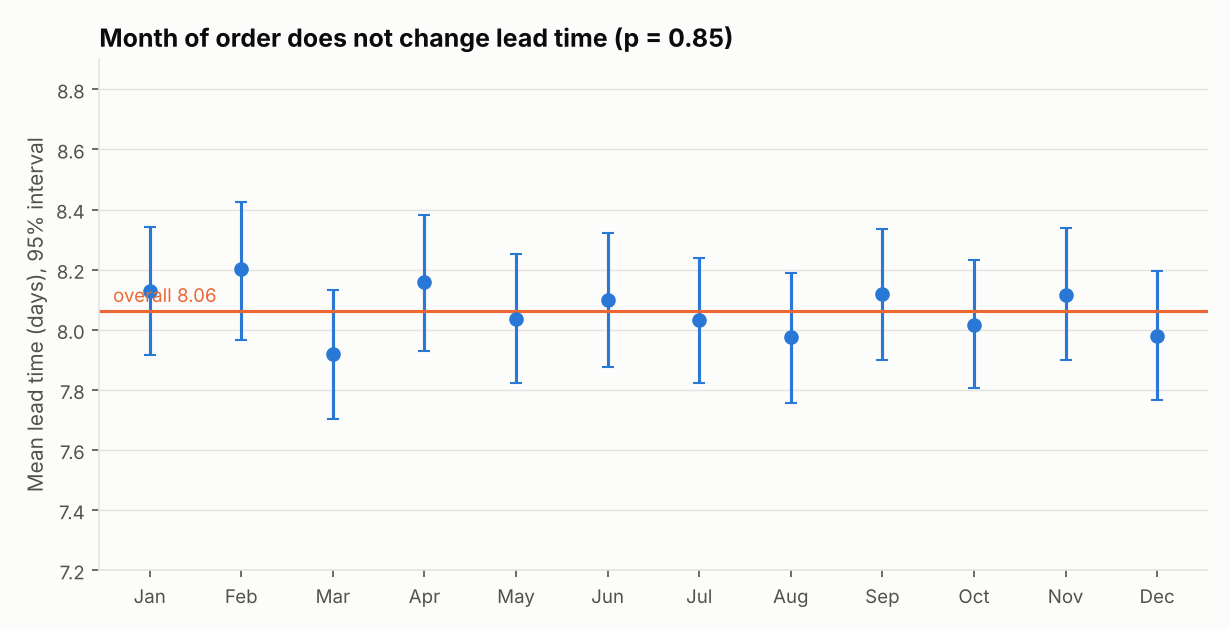

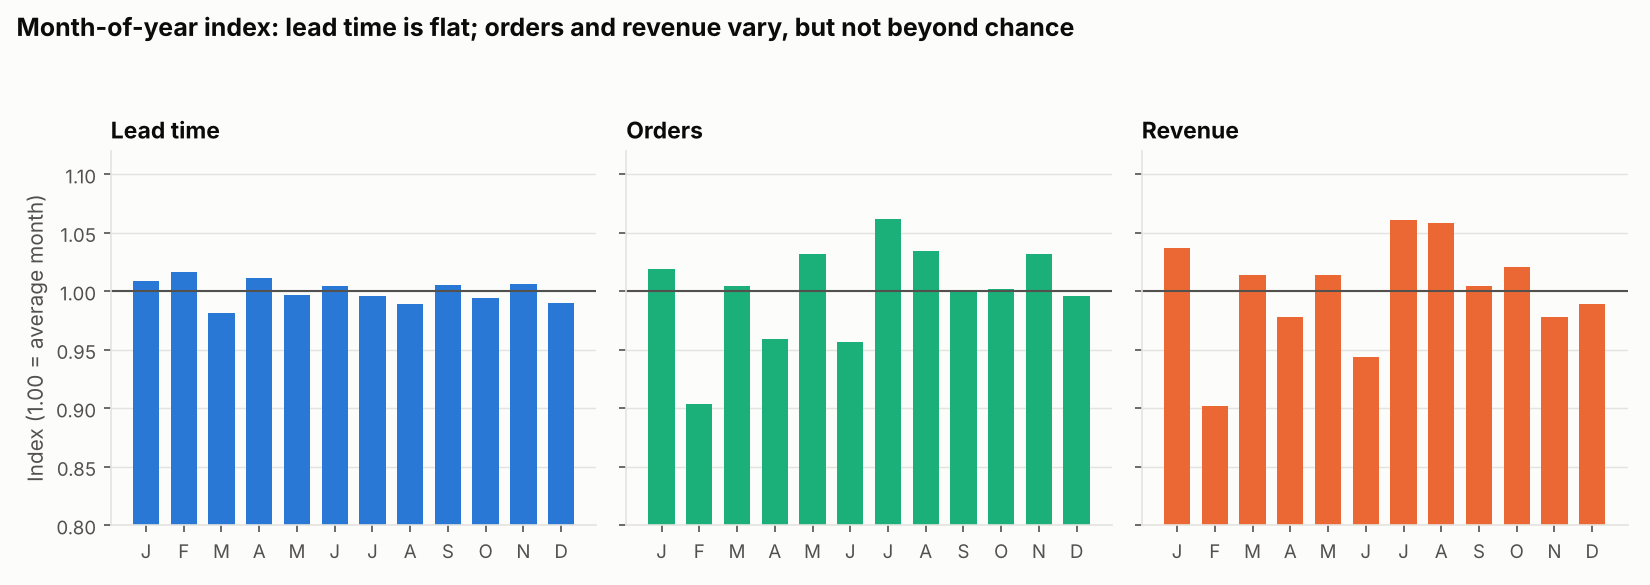

In [7]:
display(Markdown("### Q7. Is lead time seasonal?\n**No.** Lead time is an even spread of 1 to 15 days (mean 8.06). Month p = 0.85, no yearly wave, no trend by year, and a month index does not beat a plain average on a 2024 hold-out. The delivery date looks generated or planned."))
show("Q7","q7_lead_time_seasonality/q7_outputs",files=["q7_02_lead_time_by_month.csv"],charts=[],n=12)
for p in sorted((SQ/"q7_lead_time_seasonality/q7_charts").glob("*.png"))[1:3]: display(Image(filename=str(p),width=680))

### Q11. Which replenishment policy fits?
**Blocked by Q10; gate and labelled scenario only.** Ledger receipts are 18.13 times units sold; sales sit on the scale of the thresholds, purchases and current stock do not. The scenario (sales-side only) shows the existing reorder levels fill 94.3% of demand against 99.4% for a demand-based trigger at 95% service, for about 19% more stock value. It must not be quoted as a stock result.

-- q11_scale_gate.csv (11 rows)


,measure,value
0,ledger IN / OUT units,18.13
1,median sales per pair per month (units),84.30
2,median purchase receipts per pair per month (u...,1572.90
3,median max_stock,310.50
4,median reorder_level,62.00
5,median safety_stock,43.50
6,median current_stock,107790.50
7,median of per-pair current_stock / max_stock r...,349.40


-- q11_scenario_summary.csv (4 rows)


,policy,pairs,total_demand,unmet_demand,stockout_days,avg_on_hand_per_pair,orders_placed,pairs_with_fill_below_95,avg_on_hand_value_at_cost_total,fill_rate,stockout_day_share,label,assumptions
0,"A existing (reorder_level, max_stock)",180,1124832.0,64519.0,5542,152.1364,4457,72,3.925898e+08,0.9426,0.0140,SCENARIO — sales-side scale assumed; not a rep...,lost sales with no backorder; start stock = op...
1,B z=1.28 (90%),180,1124832.0,12270.0,1113,170.3423,4804,0,4.413722e+08,0.9891,0.0028,SCENARIO — sales-side scale assumed; not a rep...,lost sales with no backorder; start stock = op...
2,B z=1.645 (95%),180,1124832.0,6861.0,630,180.2971,4839,0,4.683394e+08,0.9939,0.0016,SCENARIO — sales-side scale assumed; not a rep...,lost sales with no backorder; start stock = op...
3,B z=2.33 (99%),180,1124832.0,2158.0,217,199.7031,4872,0,5.190848e+08,0.9981,0.0005,SCENARIO — sales-side scale assumed; not a rep...,lost sales with no backorder; start stock = op...


-- q11_demand_bridge_week4_vs_ledger.csv (3 rows)


,step,units_per_pair_per_month
0,"ledger OUT, median per pair per month (this no...",84.3
1,"delivered sales lines, median per pair per mon...",92.7
2,"delivered sales lines, mean per pair per month...",94.8


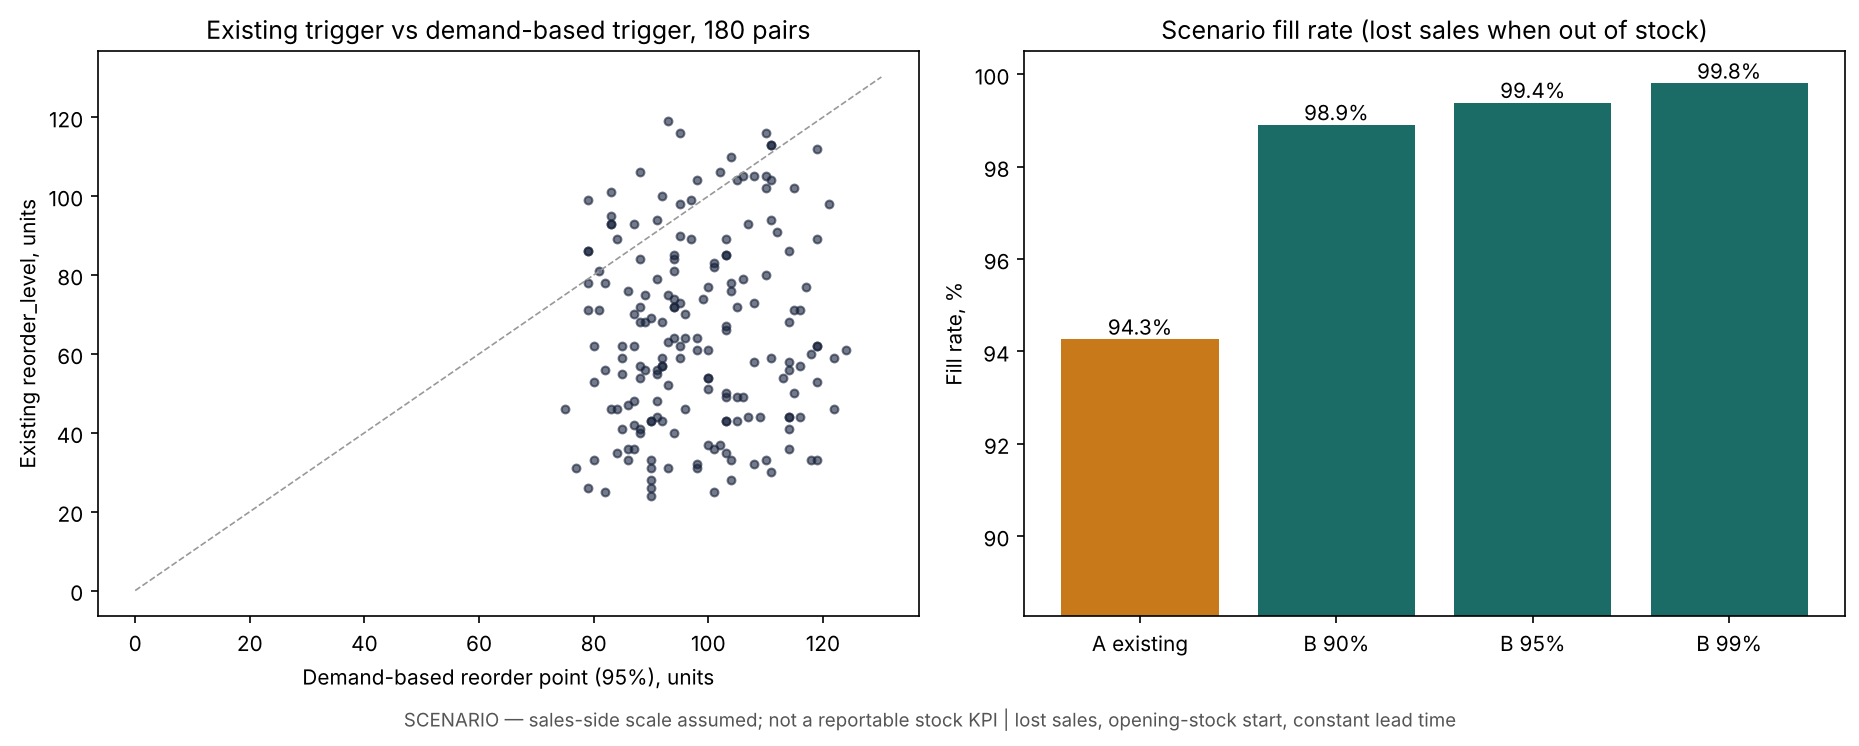

In [8]:
display(Markdown("### Q11. Which replenishment policy fits?\n**Blocked by Q10; gate and labelled scenario only.** Ledger receipts are 18.13 times units sold; sales sit on the scale of the thresholds, purchases and current stock do not. The scenario (sales-side only) shows the existing reorder levels fill 94.3% of demand against 99.4% for a demand-based trigger at 95% service, for about 19% more stock value. It must not be quoted as a stock result."))
show("Q11","q11_stock_scale_gate/q11_outputs",files=["q11_scale_gate.csv","q11_scenario_summary.csv","q11_demand_bridge_week4_vs_ledger.csv"],n=8)
for p in sorted((SQ/"q11_stock_scale_gate/q11_charts").glob("*.png")): display(Image(filename=str(p),width=680))

### Q12. Why do 14 pairs miss the ledger?
**The master is behind the ledger by its last one or two movements** (16 receipts and 1 sale, 2025-01-09 to 2025-01-24; gaps 16 to 515 units, at most 0.45%). Adjustment quantities are unsigned (1,227 added, 1,227 removed, visible only in `running_balance`) but are not the cause.

-- q12_replay_variants.csv (4 rows)


,replay,pairs_equal_ledger_last_balance,pairs_equal_inventory_master
0,replay_all_positive,0,0
1,replay_all_negative,0,0
2,replay_no_adjustment,1,1
3,replay_sign_from_balance,180,166


-- q12_mismatch_explained.csv (14 rows)


,product_id,branch_id,current_stock,ledger_latest_balance,gap,last_n_movements_explaining_gap,missing_movement_ids,missing_types,missing_reference_ids,missing_dates,net_of_missing_movements
0,P002,CHN001,105885,106182,-297,1,MOV-IN-114717,IN,PO-148144,2025-01-20,297
1,P004,PUN001,104859,105024,-165,1,MOV-IN-63458,IN,PO-541972,2025-01-18,165
2,P008,AHM001,109281,109317,-36,1,MOV-IN-135756,IN,PO-625015,2025-01-24,36
3,P010,AHM001,115149,115549,-400,2,MOV-IN-99729;MOV-IN-135755,IN;IN,PO-327036;PO-625015,2025-01-24;2025-01-24,400
4,P021,DEL001,115902,116107,-205,1,MOV-IN-114633,IN,PO-167534,2025-01-17,205
5,P023,HYD001,105798,105981,-183,1,MOV-IN-105362,IN,PO-817261,2025-01-15,183
6,P025,HYD001,113613,114128,-515,2,MOV-IN-31858;MOV-IN-42728,IN;IN,PO-236466;PO-879075,2025-01-13;2025-01-13,515
7,P026,PUN001,105190,105335,-145,1,MOV-IN-70912,IN,PO-317583,2025-01-14,145
8,P026,HYD001,108348,108546,-198,1,MOV-IN-146578,IN,PO-912346,2025-01-18,198
9,P028,DEL001,106744,106967,-223,2,MOV-IN-56490;MOV-IN-56494,IN;IN,PO-685650;PO-685650,2025-01-23;2025-01-23,223


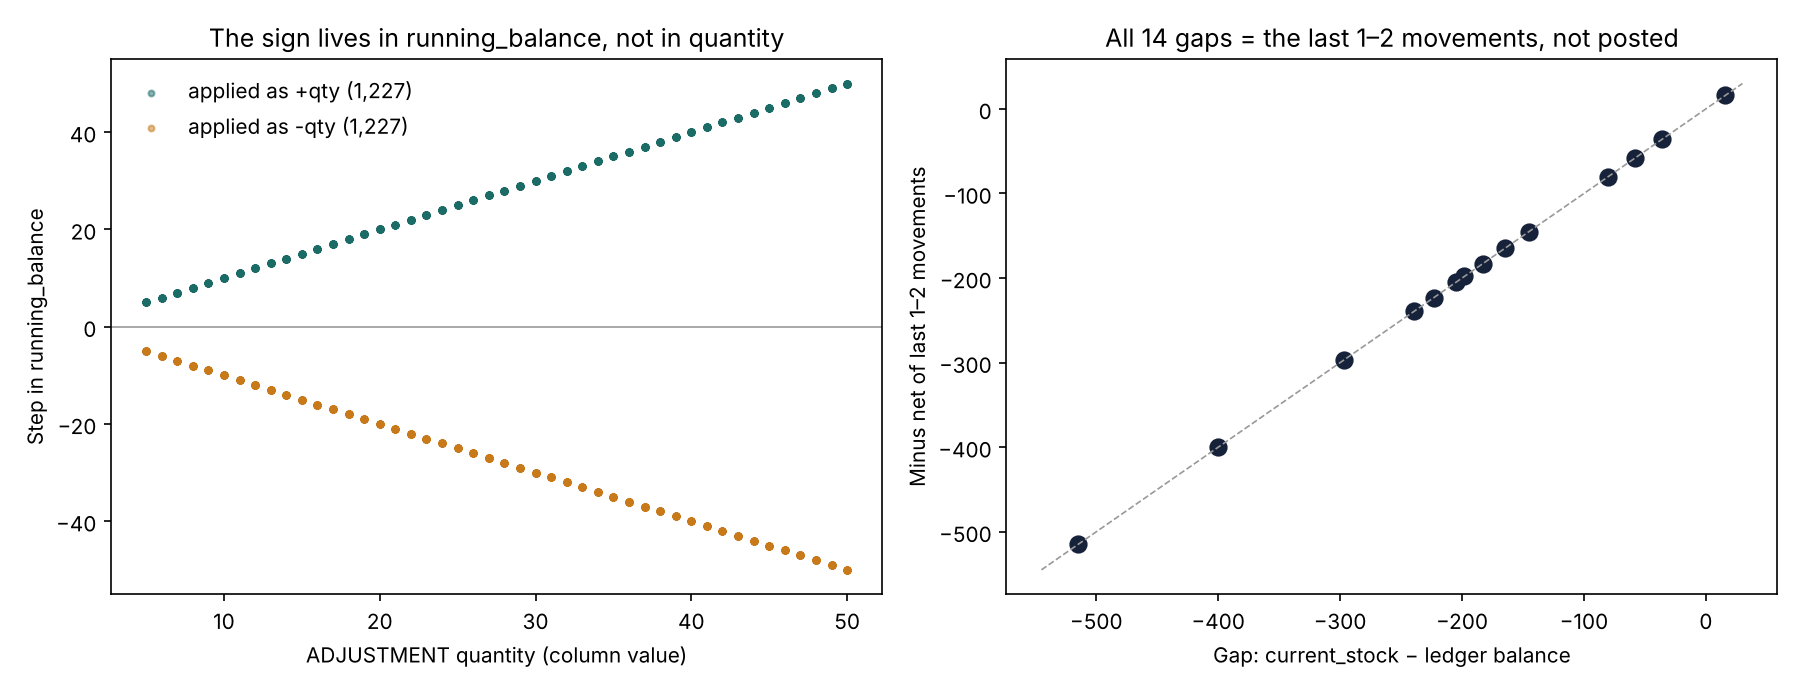

In [9]:
display(Markdown("### Q12. Why do 14 pairs miss the ledger?\n**The master is behind the ledger by its last one or two movements** (16 receipts and 1 sale, 2025-01-09 to 2025-01-24; gaps 16 to 515 units, at most 0.45%). Adjustment quantities are unsigned (1,227 added, 1,227 removed, visible only in `running_balance`) but are not the cause."))
show("Q12","q12_ledger_mismatches/q12_outputs",files=["q12_replay_variants.csv","q12_mismatch_explained.csv"],n=14)
for p in sorted((SQ/"q12_ledger_mismatches/q12_charts").glob("*.png")): display(Image(filename=str(p),width=680))

## Part 3. Data issues and questions for the data owner
**Data issues found:** cancelled orders carry a delivery date; delivery lead time is an even 0 to 15 day spread that responds to nothing; customer master dates are unreliable; every customer is active for all six years; the product master `margin_percentage` is a markup (29 of 30 products); ledger adjustment sign is stored only in `running_balance`; the Q10 purchase-order scale gap (18.1 times) is unexplained.

The full question pack with evidence is `standalone_question_reports/q11_stock_scale_gate/Data_Owner_Question_Pack.md`. Findings and recommendations: `week5_findings_summary.md`. Proposed Week 4 wording changes: `week4_corrections_proposal/`.

## Part 4. Validation summary

In [10]:
V=pd.DataFrame(checks); V.to_csv(W5/"validation_report_week05_master.csv",index=False)
print(f"{(V.Status=='PASS').sum()} of {len(V)} master checks pass; {int(S.passed.iloc[-1])} of {int(S.checks.iloc[-1])} question checks pass"); V

25 of 25 master checks pass; 167 of 167 question checks pass


,Check_Item,Expected,Actual,Status
0,Q3: notebook exists,True,True,PASS
1,Q3: notebook finishes with no error outputs,0,0,PASS
2,Q5: notebook exists,True,True,PASS
3,Q5: notebook finishes with no error outputs,0,0,PASS
4,Q6: notebook exists,True,True,PASS
5,Q6: notebook finishes with no error outputs,0,0,PASS
6,Q7: notebook exists,True,True,PASS
7,Q7: notebook finishes with no error outputs,0,0,PASS
8,Q11: notebook exists,True,True,PASS
9,Q11: notebook finishes with no error outputs,0,0,PASS
